# The FLARE pipeline: classification, uncertainty, and finding the unexpected

### ZTF Summer School: using a production classifier from start to finish

In this notebook we use the **pretrained FLARE model** in the way a survey broker would. We load
the shipped weights, classify the test split of the BTS benchmark into six classes, and read
calibrated probabilities and conformal prediction sets. We then train a small variant of FLARE
that has never seen a tidal disruption event (TDE), turn it into an **anomaly detector** with the
LUNA package, and measure how much a handful of labelled examples improves the search (active
learning).

Everything here reads the benchmark that ships inside this repository (`benchmark/`) and runs on a
CPU. The only training is a LightGBM fit of a few seconds in section 3.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex

sys.path.insert(0, "../..")          # the repository root, so that `flare` is this checkout
import flare
from flare import benchmark as B
from flare import data as D

SIX = B.SIX                          # SN_Ia, SN_CC, SLSN, AGN, TDE, CV
# one fixed colour per class: magma at six evenly spaced points, stopping before the near-white end
CLASS_COLOR = dict(zip(SIX, [to_hex(c) for c in plt.cm.magma(np.linspace(0.05, 0.85, 6))]))
BAND_COLOR = {"g": to_hex(plt.cm.magma(0.30)), "r": to_hex(plt.cm.magma(0.68))}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("FLARE", flare.__version__, "| benchmark:", B.BENCHMARK.name)
print(CLASS_COLOR)

FLARE 2.0.0 | benchmark: benchmark
{'SN_Ia': '#06051a', 'SN_CC': '#3f0f72', 'SLSN': '#802582', 'AGN': '#c23b75', 'TDE': '#f56b5c', 'CV': '#feb77e'}


## 1. Classification with the pretrained model

One call loads the shipped bts6 classifier (a five-way top level with a dedicated SLSN branch)
together with its conformal calibration. It was trained on the train and validation splits of the
benchmark, so the **test split** is the only honest place to evaluate it.

`B.load_split` returns 190 columns per object: 160 features measured on the light curve, plus the
context that is known at alert time (Pan-STARRS host galaxy, a photo-z pseudo absolute magnitude
`M_pseudo`, Gaia and WISE point-source information, and the Pan-STARRS counterpart at the
position).

In [2]:
clf = flare.load_classifier()                     # bts6, trained on train + val
X_test, y_test, test_table = B.load_split("test")
Xc = X_test.reindex(columns=clf.feature_names)

P6 = clf.predict_proba(Xc)                         # (N, 6) probabilities
pred6 = np.array([SIX.index(c) for c in clf.predict(Xc)])
print(f"{len(y_test)} test objects, {Xc.shape[1]} columns each")
print(pd.Series(np.array(SIX)[y_test]).value_counts().reindex(SIX).to_string())

1575 test objects, 190 columns each
SN_Ia    1074
SN_CC     384
SLSN       24
AGN        38
TDE        10
CV         45


In [3]:
from sklearn.metrics import (classification_report, balanced_accuracy_score,
                             f1_score, average_precision_score)

auprc = np.mean([average_precision_score((y_test == c).astype(int), P6[:, c])
                 for c in range(6)])
print(f"accuracy {(pred6 == y_test).mean():.4f} | balanced "
      f"{balanced_accuracy_score(y_test, pred6):.4f} | macro F1 "
      f"{f1_score(y_test, pred6, average='macro'):.4f} | macro AUPRC {auprc:.4f}\n")
print(classification_report(y_test, pred6, labels=range(6), target_names=SIX, digits=3))

accuracy 0.9263 | balanced 0.8428 | macro F1 0.8467 | macro AUPRC 0.8920

              precision    recall  f1-score   support

       SN_Ia      0.954     0.965     0.959      1074
       SN_CC      0.869     0.849     0.859       384
        SLSN      0.586     0.708     0.642        24
         AGN      0.917     0.868     0.892        38
         TDE      0.800     0.800     0.800        10
          CV      1.000     0.867     0.929        45

    accuracy                          0.926      1575
   macro avg      0.854     0.843     0.847      1575
weighted avg      0.927     0.926     0.926      1575



On a single split of 1,575 objects the rare classes are small (24 SLSNe, 10 TDEs), so their
scores move by several points if one object changes class. The paper quotes five-fold
out-of-fold numbers for that reason.

## 2. Not just a label: a *set* we can trust

For hard objects a single label is a guess. FLARE's conformal layer returns a **prediction set**
with a coverage guarantee per class: at `alpha = 0.1` the true class is inside the set for at least
90% of the objects of that class. A set may hold two or three classes when the model hesitates, and
it may be **empty**. An empty set means that, at this confidence level, none of the six classes fits
the object: the model abstains, and the object deserves a human look.

average set size 1.04 | empty 43, one class 1435, two classes 95, three or more 2
marginal coverage 0.897 (target 0.90)

per-class coverage:
  SN_Ia  (n=1074): 0.89
  SN_CC  (n= 384): 0.91
  SLSN   (n=  24): 0.96
  AGN    (n=  38): 0.87
  TDE    (n=  10): 0.90
  CV     (n=  45): 0.84


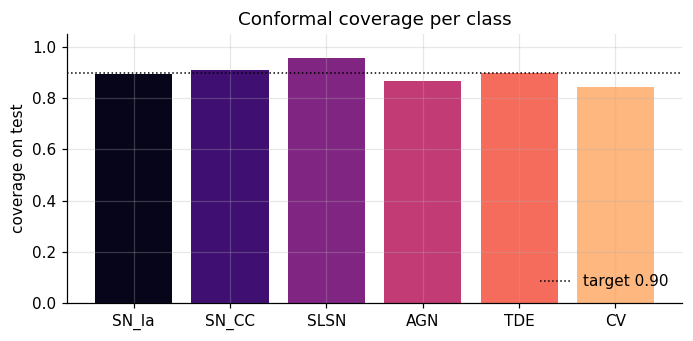

In [4]:
set_names = clf.prediction_sets(Xc, alpha=0.1)     # list of class-name lists
sets = np.array([[c in s for c in SIX] for s in set_names])
sizes = sets.sum(1)
print(f"average set size {sizes.mean():.2f} | empty {(sizes == 0).sum()}, "
      f"one class {(sizes == 1).sum()}, two classes {(sizes == 2).sum()}, "
      f"three or more {(sizes >= 3).sum()}")
print(f"marginal coverage {sets[np.arange(len(y_test)), y_test].mean():.3f} (target 0.90)\n")

cov = {c: sets[y_test == k, k].mean() for k, c in enumerate(SIX)}
print("per-class coverage:")
for k, c in enumerate(SIX):
    print(f"  {c:6s} (n={(y_test == k).sum():4d}): {cov[c]:.2f}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.bar(SIX, [cov[c] for c in SIX], color=[CLASS_COLOR[c] for c in SIX])
ax.axhline(0.9, color="k", ls=":", lw=1, label="target 0.90")
ax.set_ylim(0, 1.05); ax.set_ylabel("coverage on test"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Conformal coverage per class")
plt.tight_layout(); plt.show()

On this split the per-class coverage ranges from 0.84 (CV, 45 objects) to 0.96 (SLSN, 24
objects), around a marginal 0.897. The guarantee holds on average over calibration and test draws,
so with a few dozen objects per class a deviation of several points is expected; the paper
measures coverage with five-fold cross-validation instead.

In [5]:
# the hard objects: an empty set (abstention) or more than one candidate
empty, multi = np.where(sizes == 0)[0], np.where(sizes >= 2)[0]
for i in list(empty[:4]) + list(multi[:4]):
    shown = set_names[i] if set_names[i] else "[] (abstains)"
    print(f"  {test_table.obj_id[i]}: true={SIX[y_test[i]]:6s} argmax={SIX[P6[i].argmax()]:6s} set={shown}")

print(f"\nthe argmax is right for {(P6[empty].argmax(1) == y_test[empty]).mean():.0%} of the "
      f"{len(empty)} abstentions, against {(P6.argmax(1) == y_test).mean():.0%} overall")

# abstention is also a first anomaly signal: the benchmark's out-of-taxonomy hold-out
X_anom, _, anom_table = B.load_split("anomaly")
sets_anom = clf.prediction_sets(X_anom.reindex(columns=clf.feature_names), alpha=0.1)
print(f"empty sets: {np.mean(sizes == 0):.1%} of the test split, "
      f"{np.mean([len(s) == 0 for s in sets_anom]):.1%} of the {len(anom_table)} out-of-taxonomy objects")

  ZTF19aailvgo: true=SN_Ia  argmax=SN_Ia  set=[] (abstains)
  ZTF24aahdpki: true=SN_Ia  argmax=SN_Ia  set=[] (abstains)
  ZTF25acbxksi: true=SN_Ia  argmax=SN_Ia  set=[] (abstains)
  ZTF22abtowei: true=SN_Ia  argmax=SN_Ia  set=[] (abstains)
  ZTF25aajgcvv: true=SN_Ia  argmax=SN_Ia  set=['SN_CC', 'SLSN']
  ZTF18aagstdc: true=SN_Ia  argmax=SN_CC  set=['SN_CC', 'SLSN']
  ZTF21abrqria: true=SLSN   argmax=SLSN   set=['SN_CC', 'SLSN']
  ZTF19abzhzet: true=SN_Ia  argmax=SN_Ia  set=['SN_CC', 'SLSN']

the argmax is right for 81% of the 43 abstentions, against 93% overall


empty sets: 2.7% of the test split, 7.5% of the 53 out-of-taxonomy objects


The 43 abstentions are mostly objects the argmax gets right anyway (81%, against 93% for the
whole split), so an empty set is a warning rather than a verdict. It is also an anomaly signal:
the abstention rate is 2.7% on the test split and 7.5% on the 53 objects of the benchmark's
out-of-taxonomy hold-out, almost three times higher.

A set tells us *which* classes remain plausible. For a single object we can also ask how
uncertain each probability is. The `flare.skyportal.classify` helper, which is what FLARE returns
to SkyPortal, adds **Venn-Abers intervals**: a lower and an upper probability for every class, wide
where few calibration objects resemble this one. The same helper can use the **early models**
trained on the first 5, 10 or 20 days of a light curve; below we classify one ambiguous object
with the full light curve and again with only its first 10 days.

In [6]:
from flare import skyportal
from flare.features import extract_object_features

# the first ambiguous object whose set holds two classes, one of them the argmax
i = int([k for k in multi if sizes[k] == 2 and SIX[P6[k].argmax()] in set_names[k]][0])
path = str(B.BENCHMARK / test_table.filepath[i])
full = skyportal.classify(X_test.iloc[[i]], base_rate=0.01)

# day 10: light-curve features from the first 10 days; the context columns do not depend on time,
# except M_pseudo, which needs the peak brightness and so stays NaN (unknown) this early
x10 = pd.DataFrame([extract_object_features(path, horizon_days=10)])
for c in X_test.columns:
    if c not in x10:
        x10[c] = X_test[c].iloc[i]
x10["M_pseudo"] = np.nan
early = skyportal.classify(x10, base_rate=0.01, horizon=10)

print(f"{test_table.obj_id[i]} (true class {SIX[y_test[i]]})")
for name, out in [("full light curve", full), ("first 10 days", early)]:
    print(f"\n  {name}: predicted {out['predicted']}, set {out['prediction_set']}")
    for c in SIX:
        lo, hi = out["probability_intervals"][c]
        print(f"    {c:6s} p = {out['probabilities'][c]:.3f}   Venn-Abers [{lo:.3f}, {hi:.3f}]")

ZTF18aagstdc (true class SN_Ia)

  full light curve: predicted SN_CC, set ['SN_CC', 'SLSN']
    SN_Ia  p = 0.004   Venn-Abers [0.004, 0.008]
    SN_CC  p = 0.808   Venn-Abers [0.822, 0.827]
    SLSN   p = 0.126   Venn-Abers [0.141, 0.167]
    AGN    p = 0.059   Venn-Abers [0.019, 0.125]
    TDE    p = 0.001   Venn-Abers [0.000, 0.001]
    CV     p = 0.004   Venn-Abers [0.001, 0.004]

  first 10 days: predicted SN_Ia, set ['SN_Ia', 'SN_CC', 'SLSN', 'TDE']
    SN_Ia  p = 0.540   Venn-Abers [0.589, 0.593]
    SN_CC  p = 0.276   Venn-Abers [0.220, 0.223]
    SLSN   p = 0.102   Venn-Abers [0.067, 0.071]
    AGN    p = 0.039   Venn-Abers [0.054, 0.063]
    TDE    p = 0.021   Venn-Abers [0.052, 0.059]
    CV     p = 0.022   Venn-Abers [0.040, 0.069]


ZTF18aagstdc is a SN Ia that the full-curve model calls SN_CC, with a set that misses the true
class: one of the misses that a 90% guarantee allows. With only its first 10 days, the early model
hedges over four classes and puts SN Ia first. The Venn-Abers intervals are narrow where many
calibration objects resemble the object (SN_CC, [0.822, 0.827]) and wide where few do (AGN,
[0.019, 0.125]).

## 3. The classifier that has never seen a TDE

Now the anomaly experiment. `train_no_tde.py` trains a variant of FLARE with **every TDE
removed** from the train and validation splits, leaving five classes. To this model, tidal
disruption events do not exist. What does it do when it meets one?

The model reads the 160 light-curve features plus the host and Gaia/WISE blocks, which is the same
space FLARE's own anomaly layer uses (the photo-z magnitude and the Pan-STARRS counterpart help
classification but harm blind detection). It trains in a few seconds.

In [7]:
from train_no_tde import fit_no_tde, feature_columns, KNOWN

import time
t0 = time.time()
clf5, info = fit_no_tde()
print(f"trained in {time.time() - t0:.0f} s")                          # KNOWN = SN_Ia, SN_CC, SLSN, AGN, CV
AD_COLS = feature_columns(X_test)                  # 160 light-curve + 21 context columns
TDE = SIX.index("TDE")

is_tde = y_test == TDE
P5 = clf5.predict(X_test[AD_COLS])                 # (N, 5): TDE is not an option
tab = pd.DataFrame(P5[is_tde], columns=KNOWN, index=test_table.obj_id[is_tde]).round(2)
tab["prediction"] = [KNOWN[k] for k in P5[is_tde].argmax(1)]
print(tab.to_string())
print(f"\nmean confidence on the {is_tde.sum()} test TDEs: {P5[is_tde].max(1).mean():.2f}")
print(f"mean confidence on everything else : {P5[~is_tde].max(1).mean():.2f}")

train (7300, 181) (TDEs removed: 47), val (1564, 181) (TDEs removed: 11)
best iteration 124; five-class val accuracy (no TDEs anywhere): 0.9316
trained in 9 s
              SN_Ia  SN_CC  SLSN   AGN    CV prediction
obj_id                                                 
ZTF20acqoiyt   0.86   0.10  0.01  0.03  0.00      SN_Ia
ZTF18abxnvoz   0.21   0.14  0.02  0.51  0.12        AGN
ZTF22aavvqyh   0.38   0.39  0.10  0.10  0.04      SN_CC
ZTF22abkfhua   0.02   0.69  0.02  0.26  0.01      SN_CC
ZTF20acaazkt   0.56   0.31  0.03  0.09  0.01      SN_Ia
ZTF26aaoebni   0.01   0.98  0.01  0.00  0.00      SN_CC
ZTF24aaecooj   0.04   0.93  0.01  0.01  0.00      SN_CC
ZTF22aaigqsr   0.49   0.34  0.01  0.15  0.01      SN_Ia
ZTF24abjfuew   0.35   0.60  0.04  0.01  0.01      SN_CC
ZTF20achpcvt   0.55   0.38  0.01  0.05  0.02      SN_Ia

mean confidence on the 10 test TDEs: 0.66
mean confidence on everything else : 0.93


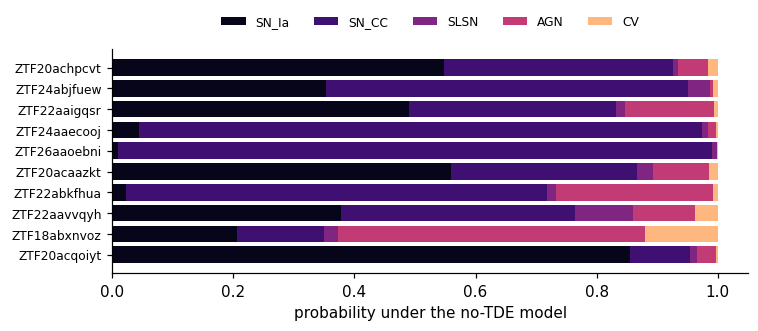

In [8]:
# where the TDEs go: probability given to each known class
fig, ax = plt.subplots(figsize=(7, 3.2))
left = np.zeros(is_tde.sum())
for k, c in enumerate(KNOWN):
    ax.barh(range(is_tde.sum()), P5[is_tde, k], left=left, color=CLASS_COLOR[c], label=c)
    left += P5[is_tde, k]
ax.set_yticks(range(is_tde.sum())); ax.set_yticklabels(test_table.obj_id[is_tde], fontsize=8)
ax.set_xlabel("probability under the no-TDE model"); ax.grid(False)
ax.legend(frameon=False, ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.2))
plt.tight_layout(); plt.show()

The model cannot name what it has never seen, but it is measurably **less confident**. That drop
in confidence is a signal, and LUNA turns signals like it into a systematic detector.

## 4. LUNA: many ways to be surprised

LUNA fits an ensemble of anomaly scorers on the "normal" world (the five known classes of the train
split) and scores a **discovery pool**: the whole test split plus the 47 training TDEs we removed,
which gives 57 hidden TDEs among 1,622 objects. No object in the pool was used to fit the model or
the scorers. Each scorer reads either the scaled features (the embedding) or the model's raw
scores (the logits).

In [9]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from luna.pipeline import LUNAPipeline

X_train, y_train, train_table = B.load_split("train")
known = y_train != TDE
Xtr_known = X_train.loc[known, AD_COLS]
y5_train = np.array([KNOWN.index(SIX[k]) for k in y_train[known]])

imputer = SimpleImputer(strategy="median").fit(Xtr_known)
scaler = RobustScaler().fit(imputer.transform(Xtr_known))
embed = lambda Xdf: np.clip(scaler.transform(imputer.transform(Xdf[AD_COLS])), -10, 10)
logits = lambda Xdf: clf5.predict(Xdf[AD_COLS], raw_score=True)

train_data = {"embeddings": embed(Xtr_known), "labels": y5_train, "logits": logits(Xtr_known)}

# the discovery pool: test split + the training TDEs the model never saw
X_pool = pd.concat([X_test[AD_COLS], X_train.loc[~known, AD_COLS]], ignore_index=True)
pool_table = pd.concat([test_table, train_table[~known]], ignore_index=True)
truth_pool = np.concatenate([np.array(SIX)[y_test], ["TDE"] * (~known).sum()])
is_tde_pool = truth_pool == "TDE"

query_data = {"embeddings": embed(X_pool), "logits": logits(X_pool)}
print(f"LUNA train: {train_data['embeddings'].shape} | pool: "
      f"{len(X_pool)} objects, {is_tde_pool.sum()} hidden TDEs")

LUNA train: (7300, 181) | pool: 1622 objects, 57 hidden TDEs


In [10]:
pipe = LUNAPipeline(target_far=0.01)
pipe.fit(train_data)
scores = pipe.score(query_data)
print("scorers:", list(scores))

  [LUNA] fit msp in 0.0s


  [LUNA] fit entropy in 0.0s


  [LUNA] fit energy in 0.0s


  [LUNA] fit odin in 0.0s


  [LUNA] fit mahal_global in 0.1s


...

  [LUNA] fit lof in 6.6s


  [LUNA] fit pca_recon in 0.2s


  [LUNA] fit mrs in 0.4s


  [LUNA] Fitted 14 scorers: ['msp', 'entropy', 'energy', 'odin', 'mahal_global', 'mahal_class', 'mahal_within', 'knn', 'typicality', 'gmm', 'iforest', 'lof', 'pca_recon', 'mrs']


scorers: ['msp', 'entropy', 'energy', 'odin', 'mahal_global', 'mahal_class', 'mahal_within', 'knn', 'typicality', 'gmm', 'iforest', 'lof', 'pca_recon', 'mrs']


## 5. Stage 1: blind discovery

No anomaly labels at all: we average the ranks across all scorers and look at the top of the
list.

In [11]:
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

R = np.mean([rankdata(scores[k]) for k in scores], axis=0)
order = np.argsort(R)[::-1]

topk = 40
print(f"top-{topk} blind anomalies contain {is_tde_pool[order[:topk]].sum()}/{is_tde_pool.sum()} "
      f"hidden TDEs (chance: {topk * is_tde_pool.mean():.1f})")
print(f"blind consensus AUC: {roc_auc_score(is_tde_pool, R):.3f}")
print("\nAUC of each scorer on its own:")
for k in sorted(scores, key=lambda k: -roc_auc_score(is_tde_pool, scores[k])):
    print(f"  {k:13s} {roc_auc_score(is_tde_pool, scores[k]):.3f}")

top-40 blind anomalies contain 5/57 hidden TDEs (chance: 1.4)
blind consensus AUC: 0.753

AUC of each scorer on its own:
  energy        0.971
  entropy       0.935
  odin          0.926
  msp           0.907
  lof           0.718
  gmm           0.702
  knn           0.650
  mrs           0.606
  iforest       0.590
  mahal_global  0.563
  mahal_within  0.555
  mahal_class   0.548
  pca_recon     0.532
  typicality    0.505


The average hides a split. The four scorers that read the logits (energy, entropy, ODIN and the
maximum softmax probability, MSP) rank the hidden TDEs well, with AUC from 0.907 to 0.971, while
the other ten scorers (distance, density and hybrid scorers built on the features) stay between
0.505 and 0.718 and drag the consensus down to 0.753. Ranking the scorers this way uses the pool labels, which a blind search
does not have, so the table is a diagnosis rather than a method. FLARE's own anomaly layer uses
the energy score because a scorer study on other data chose it.

## 6. Stage 2: active learning with eleven labels

In a real survey we eventually confirm a few anomalies spectroscopically. We feed those back:
LUNA's supervised combiner learns how to *weight* the scorers, using the validation split (its
known-class objects as normal, its 11 TDEs as confirmed anomalies). The pool stays untouched.

In [12]:
X_val, y_val, _ = B.load_split("val")
val_tde = y_val == TDE
id_data = {"embeddings": embed(X_val[~val_tde]), "logits": logits(X_val[~val_tde])}
ood_data = {"embeddings": embed(X_val[val_tde]), "logits": logits(X_val[val_tde])}
print(f"combiner training: {(~val_tde).sum()} normal + {val_tde.sum()} confirmed TDEs")

pipe.fit_combiner(id_data, ood_data, verbose=False)
out = pipe.predict(query_data)
es = out["ensemble_score"]

print(f"\nsupervised AUC: {roc_auc_score(is_tde_pool, es):.3f}"
      f"   (blind was {roc_auc_score(is_tde_pool, R):.3f})")
flag = out["flagged"]
print(f"flagged at 1% FAR: {flag.sum()} objects, containing "
      f"{is_tde_pool[flag].sum()}/{is_tde_pool.sum()} hidden TDEs")
o_es = np.argsort(es)[::-1]
print(f"top-{topk} after active learning: {is_tde_pool[o_es[:topk]].sum()}/{is_tde_pool.sum()} hidden TDEs")
o_en = np.argsort(scores["energy"])[::-1]
print(f"for reference, energy alone: AUC {roc_auc_score(is_tde_pool, scores['energy']):.3f}, "
      f"top-{topk} {is_tde_pool[o_en[:topk]].sum()}/{is_tde_pool.sum()}")

combiner training: 1564 normal + 11 confirmed TDEs



supervised AUC: 0.918   (blind was 0.753)
flagged at 1% FAR: 70 objects, containing 38/57 hidden TDEs
top-40 after active learning: 27/57 hidden TDEs
for reference, energy alone: AUC 0.971, top-40 29/57


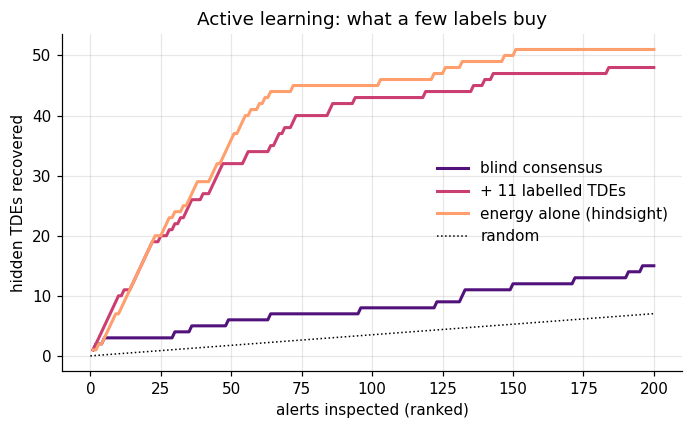

In [13]:
# the discovery curve: TDEs found against alerts inspected
fig, ax = plt.subplots(figsize=(6.4, 4))
for score, lab, colr in [(R, "blind consensus", plt.cm.magma(0.25)),
                         (es, f"+ {val_tde.sum()} labelled TDEs", plt.cm.magma(0.55)),
                         (scores["energy"], "energy alone (hindsight)", plt.cm.magma(0.8))]:
    o = np.argsort(score)[::-1]
    ax.plot(np.arange(1, 201), np.cumsum(is_tde_pool[o])[:200], lw=2, color=colr, label=lab)
ax.plot([0, 200], [0, 200 * is_tde_pool.mean()], "k:", lw=1, label="random")
ax.set_xlabel("alerts inspected (ranked)")
ax.set_ylabel("hidden TDEs recovered")
ax.legend(frameon=False)
ax.set_title("Active learning: what a few labels buy")
plt.tight_layout(); plt.show()

Eleven labels move the AUC from 0.753 to 0.918 and the hidden TDEs in the top 40 from 5 to 27:
the combiner learns from a handful of confirmed objects which scorers to trust. It still stays
below the energy score alone (AUC 0.971, 29 of 57 in the top 40), because eleven
examples are few to weight fourteen scorers, and the combiner cannot know in advance what the
hindsight table told us. Closing that gap without peeking at the pool is one of the hackathon
tasks.

## 7. Hackathon hand-off: the real intruders

Everything above hunted TDEs, a class we *chose* to hide. The `rare_transients/` folder holds
eight peculiar transients downloaded from public brokers (two fast blue optical transients, three
calcium-rich transients, an intermediate-luminosity red transient, a hydrogen-poor superluminous
supernova and a SN Iax). Before we treat them as intruders we check where they sit in the
benchmark, because the six-class taxonomy is wider than the legacy five-class one.

      obj_id      name literature class benchmark split  BTS type six-class label
ZTF18abcfcoo AT2018cow             FBOT         anomaly      FBOT            None
ZTF19aadyppr AT2019abn             ILRT         anomaly      ILRT            None
ZTF19aatesgp SN2019ehk          Ca-rich             val     SN Ib           SN_CC
ZTF20aahbfmf SN2020ank           SLSN-I           train    SLSN-I            SLSN
ZTF20abjbgjj SN2020kyg           SN Iax           train     SN II           SN_CC
ZTF21aakilyd AT2021csp             FBOT           train    SN Icn           SN_CC
ZTF21aaqhhfu SN2021gno          Ca-rich           train     SN Ib           SN_CC
ZTF22aasxgjp SN2022oqm          Ca-rich           train SN Ic-pec           SN_CC


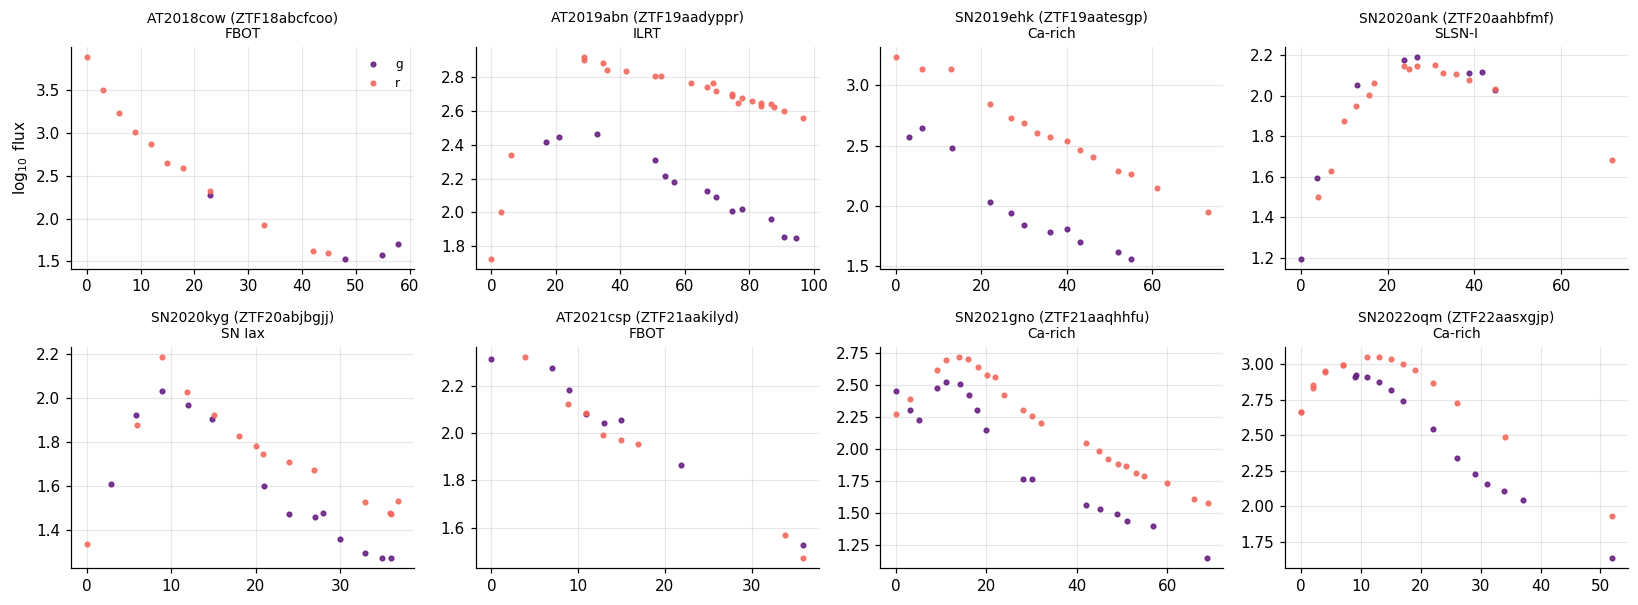

In [14]:
import json, glob
meta = json.load(open("rare_transients/meta.json"))
files = sorted(glob.glob("rare_transients/*.npz"))
where = pd.concat([pd.read_csv(B.BENCHMARK / "splits" / f"{s}.csv").assign(split=s)
                   for s in ["train", "val", "test", "anomaly"]]).set_index("obj_id")
rows = []
for f in files:
    oid = f.split("/")[-1].replace(".npz", "")
    r = where.loc[oid] if oid in where.index else None
    rows.append({"obj_id": oid, "name": meta[oid]["name"], "literature class": meta[oid]["class"],
                 "benchmark split": None if r is None else r.split,
                 "BTS type": None if r is None else r.bts_type,
                 "six-class label": None if r is None or pd.isna(r.cls) else r.cls})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(2, 4, figsize=(15, 5.6))
for ax, f in zip(axes.ravel(), files):
    oid = f.split("/")[-1].replace(".npz", "")
    bands = D.reconstruct_bands(D.load_events(f))
    for name in ["g", "r"]:
        if name in bands:
            ax.plot(bands[name].t, bands[name].logflux, "o", ms=3, color=BAND_COLOR[name],
                    alpha=0.85, label=name)
    ax.set_title(f"{meta[oid]['name']} ({oid})\n{meta[oid]['class']}", fontsize=9)
axes[0, 0].legend(frameon=False, fontsize=8); axes[0, 0].set_ylabel(r"$\log_{10}$ flux")
plt.tight_layout(); plt.show()

Six of the eight carry an in-taxonomy BTS label (SN_CC or SLSN) and sit in the train or
validation split, so the shipped classifier and the no-TDE model have both trained on them. Only
AT2018cow (FBOT) and AT2019abn (ILRT) are out of taxonomy, and both belong to the benchmark's
**anomaly split**: 53 objects outside the six classes, of which 37 are novae (role
`ambiguous`, because a nova looks much like a CV outburst) and 16 are rarer families (role
`novel`). The cell below scores that split with FLARE's shipped anomaly energy, against a threshold
set at a 1% false-alarm rate on the known-class test objects. This is the baseline for the
hackathon.

In [15]:
E_test = clf.anomaly_energy(X_test)
E_anom = clf.anomaly_energy(X_anom)
thr = np.percentile(E_test, 99)
print(f"anomaly energy AUC, anomaly split against test: "
      f"{roc_auc_score(np.r_[np.zeros(len(E_test)), np.ones(len(E_anom))], np.r_[E_test, E_anom]):.3f}")
fam = (anom_table.assign(flagged=E_anom > thr)
       .groupby(["role", "bts_type"]).flagged.agg(["size", "sum"])
       .rename(columns={"size": "objects", "sum": "above 1% FAR"}))
print(fam.to_string())

anomaly energy AUC, anomaly split against test: 0.799
                    objects  above 1% FAR
role      bts_type                       
ambiguous nova           37             1
novel     Ca-rich         2             0
          FBOT            1             0
          ILRT            3             0
          LBV             6             0
          LRN             4             0


The energy ranks the out-of-taxonomy objects above most test objects (AUC 0.799), yet at a 1%
false-alarm rate it flags only 1 of the 53. These families sit close to the known classes in
feature space, which is what makes them a good hackathon target.

### Our tasks (hackathon)

1. **Score the intruders.** Take the 53 objects of `B.load_split("anomaly")` (they include
   AT2018cow and AT2019abn from `rare_transients/`), build a `query_data` dictionary as in
   section 4, and push them through both the blind consensus and the supervised combiner. At what
   percentile of the pool does each family land? For the broker light curves in
   `rare_transients/`, `clf.features_from_files(files)` gives the light-curve features with the
   context columns left as NaN (unknown), which is how FLARE expects missing context: does the
   score of AT2018cow change between the benchmark and the broker version?
2. **Which ones hide, and why?** For any intruder that does *not* stand out, look at its light
   curve and its nearest neighbours in feature space. What is it mimicking? Novae against CVs is
   the obvious place to start.
3. **Improve the detector.** Anything is allowed except touching the pool labels: drop or add
   scorers, change the combiner, engineer a feature aimed at the family that hides, or try to
   reach the energy score's 0.971 on the hidden-TDE pool without using the pool labels. Report the
   AUC on the hidden-TDE pool *and* the intruder percentiles: did a change help both, or did it
   trade one for the other?
4. **(Open question)** Repeat section 6 with a *different* label budget: what happens with 3
   labelled TDEs instead of 11? With all 47 training TDEs (then remove them from the pool)? Plot
   AUC against the number of labels, the value-of-labels curve of active learning.

Honest nulls are welcome. A clean "this scorer does not help, here is the comparison" is a real
result.